# Imports

In [10]:
import time
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)
K, Gama, lam = 1.0, 1.0, 1.0     # uteži energije (kot na vaji 05)
R, n = 1.0, 6                    # polmer in število oglišč celice

# Funkcije

In [11]:
# --- Model celice z vaje 05 ---
def poligon(R, n, eps=0.0, rng=rng):
    dfi = 2 * np.pi / n
    fi = dfi * np.arange(n) + rng.uniform(-eps, eps, n) * dfi
    r = R * (1 + rng.uniform(-eps, eps, n))
    return np.column_stack([r * np.cos(fi), r * np.sin(fi)])


def stranice(t):
    return np.linalg.norm(np.roll(t, -1, axis=0) - t, axis=1)


def obseg(t):
    return stranice(t).sum()


def ploscina(t):
    x, y = t[:, 0], t[:, 1]
    return 0.5 * abs(np.sum(x * np.roll(y, -1) - np.roll(x, -1) * y))


def tezisce(t):
    return t.mean(axis=0)


def referencne(R, n):
    l0 = 2 * R * np.sin(np.pi / n)
    return 0.5 * n * R**2 * np.sin(2 * np.pi / n), n * l0, l0


def energija(t, ref):
    A0, P0, l0 = ref
    return (0.5 * K * (ploscina(t) - A0)**2 + 0.5 * Gama * (obseg(t) - P0)**2
            + 0.5 * lam * np.sum((stranice(t) - l0)**2))


def narisi_celico(ax, t, barva="tab:orange", **kw):
    z = np.vstack([t, t[:1]])
    ax.fill(z[:, 0], z[:, 1], color=barva, alpha=0.3)
    ax.plot(z[:, 0], z[:, 1], "o-", color=barva, ms=3, **kw)
    ax.set_aspect("equal")


# --- Gradientni spust ---
def gs_1d(x, k, eta, n_iter=50, x0=1.0):
    """Gradientni spust za E(x) = k (x - x0)^2. Vrne zaporedje x."""
    pot = [x]
    for _ in range(n_iter):
        x = x - eta * 2 * k * (x - x0)
        pot.append(x)
    return np.array(pot)


def gradient(t, ref, h=1e-6):
    """Numerični gradient energije po vseh koordinatah (centralne diference). Vrne array (n, 2)."""
    g = np.zeros_like(t)
    for i in range(len(t)):
        for d in range(2):
            tp, tm = t.copy(), t.copy()
            tp[i, d] += h
            tm[i, d] -= h
            g[i, d] = (energija(tp, ref) - energija(tm, ref)) / (2 * h)
    return g


def gradient_ploscine(t):
    """Analitični gradient ploščine: dA/dx_i = (y_{i+1} - y_{i-1})/2, dA/dy_i = (x_{i-1} - x_{i+1})/2."""
    x, y = t[:, 0], t[:, 1]
    return 0.5 * np.column_stack([np.roll(y, -1) - np.roll(y, 1), np.roll(x, 1) - np.roll(x, -1)])


def gradientni_spust(t, ref, eta=0.05, n_iter=2000, tol=1e-10):
    """Relaksacija celice z gradientnim spustom. Konča, ko je E < tol.
    Vrne (t, zgodovina E, zgodovina |grad E|)."""
    t = t.copy()
    zE, zg = [energija(t, ref)], []
    for _ in range(n_iter):
        g = gradient(t, ref)
        t -= eta * g
        zE.append(energija(t, ref))
        zg.append(np.linalg.norm(g))
        if zE[-1] < tol:
            break
    return t, np.array(zE), np.array(zg)


# --- Tkivo: skupni seznam točk, celice so seznami indeksov točk (v pozitivni smeri) ---
def referenca(A0, n):
    """Referenčne vrednosti (A0, P0, l0) pravilnega n-kotnika s ploščino A0."""
    Rr = np.sqrt(2 * A0 / (n * np.sin(2 * np.pi / n)))
    l0 = 2 * Rr * np.sin(np.pi / n)
    return A0, n * l0, l0


def energija_tkiva(tocke, celice, A0):
    """Vsota energij vseh celic; celica k ima referenčno ploščino A0[k]."""
    return sum(energija(tocke[c], referenca(A0[k], len(c))) for k, c in enumerate(celice))


def gradient_tkiva(tocke, celice, A0, h=1e-6):
    """Numerični gradient energije tkiva po vseh točkah. Točka vpliva le na celice, ki jo vsebujejo."""
    g = np.zeros_like(tocke)
    for i in range(len(tocke)):
        moje = [k for k, c in enumerate(celice) if i in c]
        for d in range(2):
            tp, tm = tocke.copy(), tocke.copy()
            tp[i, d] += h
            tm[i, d] -= h
            g[i, d] = sum(energija(tp[celice[k]], referenca(A0[k], len(celice[k])))
                          - energija(tm[celice[k]], referenca(A0[k], len(celice[k]))) for k in moje) / (2 * h)
    return g


def relaksacija_tkiva(tocke, celice, A0, eta=0.05, n_iter=1000, tol=1e-10):
    """Gradientni spust za vse točke tkiva. Skupne točke se premikajo hkrati za vse celice."""
    tocke = tocke.copy()
    zE = [energija_tkiva(tocke, celice, A0)]
    for _ in range(n_iter):
        tocke -= eta * gradient_tkiva(tocke, celice, A0)
        zE.append(energija_tkiva(tocke, celice, A0))
        if zE[-1] < tol:
            break
    return tocke, np.array(zE)


def rast(tocke, celice, A0, rastoce, faktor=2.0, koraki=10, eta=0.05):
    """Referenčno ploščino celic iz seznama rastoce v korakih poveča za faktor; po vsakem koraku
    relaksira tkivo. Vrne (tocke, nov A0, ploščine rastočih celic po korakih)."""
    A0 = list(A0)
    zacetne = {k: A0[k] for k in rastoce}
    zg = [[ploscina(tocke[celice[k]]) for k in rastoce]]
    for s in range(1, koraki + 1):
        for k in rastoce:
            A0[k] = zacetne[k] * (1 + (faktor - 1) * s / koraki)
        tocke, _ = relaksacija_tkiva(tocke, celice, A0, eta=eta, n_iter=300, tol=1e-12)
        zg.append([ploscina(tocke[celice[k]]) for k in rastoce])
    return tocke, A0, np.array(zg)


def vstavi_v_sosede(celice, a, b, nova, razen):
    """Točko nova vstavi med točki a in b v vseh celicah (razen celice razen), ki imajo stranico (a, b)."""
    for k, c in enumerate(celice):
        if k == razen:
            continue
        for i in range(len(c)):
            if {c[i], c[(i + 1) % len(c)]} == {a, b}:
                c.insert(i + 1, nova)      # pri paru (zadnja, prva) se točka doda na konec
                break


def deli_celico(tocke, celice, k, kot):
    """Celico k razdeli s premico skozi njeno težišče s smerjo kot (radiani).
    Na obeh presekanih stranicah ustvari novo točko in jo vstavi tudi v sosednjo celico.
    Celico k nadomesti prva hči, druga hči se doda na konec seznama celic.
    Hčeri si delita stranico med novima točkama. Vrne (tocke, celice, (m1, m2))."""
    c = list(celice[k])
    P = tocke[c]
    nor = np.array([-np.sin(kot), np.cos(kot)])      # normala premice
    s = (P - tezisce(P)) @ nor                       # predznačena razdalja oglišč od premice
    presek = []                                      # (položaj stranice v celici, indeks nove točke)
    for i in range(len(c)):
        j = (i + 1) % len(c)
        if s[i] * s[j] < 0:                          # stranica (c[i], c[j]) seka premico
            p = P[i] + s[i] / (s[i] - s[j]) * (P[j] - P[i])
            tocke = np.vstack([tocke, p])
            m = len(tocke) - 1
            presek.append((i, m))
            vstavi_v_sosede(celice, c[i], c[j], m, razen=k)
    (i1, m1), (i2, m2) = presek
    celice[k] = [m1] + c[i1 + 1:i2 + 1] + [m2]
    celice.append([m2] + c[i2 + 1:] + c[:i1 + 1] + [m1])
    return tocke, celice, (m1, m2)


def narisi_tkivo(ax, tocke, celice, oznake=False):
    barve = plt.cm.tab10(np.arange(len(celice)) % 10)
    for c, b in zip(celice, barve):
        narisi_celico(ax, tocke[c], b)
    if oznake:
        for i, p in enumerate(tocke):
            ax.annotate(str(i), p, fontsize=7, xytext=(3, 3), textcoords="offset points")


def dolga_os(t):
    """Smer (kot) dolge osi celice iz lastnih vektorjev kovariančne matrike oglišč."""
    w, v = np.linalg.eigh(np.cov((t - tezisce(t)).T))
    return np.arctan2(v[1, -1], v[0, -1])

# Testno območje

In [12]:
ref = referencne(R, n)
t0 = poligon(R, n, eps=0.3, rng=np.random.default_rng(7))

# Analitični in numerični gradient ploščine (K = 1, ostali uteži 0 -> dE/dr = (A - A0) dA/dr)
g_num = np.zeros_like(t0)
for i in range(n):
    for d in range(2):
        tp, tm = t0.copy(), t0.copy()
        tp[i, d] += 1e-6
        tm[i, d] -= 1e-6
        g_num[i, d] = (ploscina(tp) - ploscina(tm)) / 2e-6
print("max |dA analitično - numerično| =", np.abs(gradient_ploscine(t0) - g_num).max())

# P4: delitev kvadrata s premico y = 0
tk, ck, _ = deli_celico(np.array([[1, 1], [-1, 1], [-1, -1], [1, -1]], dtype=float), [[0, 1, 2, 3]], 0, 0.0)
print("hčeri kvadrata:", ck, [ploscina(tk[c]) for c in ck], "skupni točki:", sorted(set(ck[0]) & set(ck[1])))

max |dA analitično - numerično| = 2.893539852166782e-10
hčeri kvadrata: [[4, 2, 3, 5], [5, 0, 1, 4]] [np.float64(2.0), np.float64(2.0)] skupni točki: [4, 5]


# Naloga 1 - Slika 2

eta = 0.01: x_40 = 1.000e+00, razmerje |x_n+1 - x0|/|x_n - x0| = 0.800, 1 - 2 k eta = +0.80
eta = 0.04: x_40 = 1.000e+00, razmerje |x_n+1 - x0|/|x_n - x0| = 0.200, 1 - 2 k eta = +0.20
eta = 0.06: x_40 = 1.000e+00, razmerje |x_n+1 - x0|/|x_n - x0| = 0.200, 1 - 2 k eta = -0.20
eta = 0.09: x_40 = 1.000e+00, razmerje |x_n+1 - x0|/|x_n - x0| = 0.800, 1 - 2 k eta = -0.80
eta = 0.11: x_40 = 1.471e+03, razmerje |x_n+1 - x0|/|x_n - x0| = 1.200, 1 - 2 k eta = -1.20


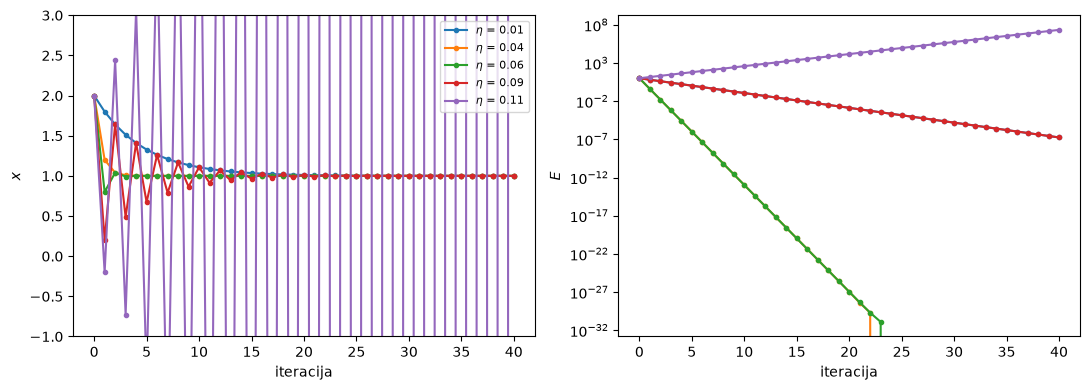

In [13]:
k1 = 10.0
etas = [0.01, 0.04, 0.06, 0.09, 0.11]
fig = plt.figure(figsize=(11, 4))
ax1 = fig.add_subplot(121)
ax2 = fig.add_subplot(122)
for eta in etas:
    pot = gs_1d(2.0, k1, eta, n_iter=40)
    E = k1 * (pot - 1)**2
    ax1.plot(pot, ".-", label=f"$\\eta$ = {eta}")
    ax2.semilogy(E, ".-", label=f"$\\eta$ = {eta}")
    q = abs(pot[2] - 1) / abs(pot[1] - 1)
    print(f"eta = {eta}: x_40 = {pot[-1]:.3e}, razmerje |x_n+1 - x0|/|x_n - x0| = {q:.3f}, 1 - 2 k eta = {1 - 2*k1*eta:+.2f}")
ax1.set_ylim(-1, 3)
ax1.set_xlabel("iteracija")
ax1.set_ylabel("$x$")
ax1.legend(fontsize=8)
ax2.set_xlabel("iteracija")
ax2.set_ylabel("$E$")
fig.tight_layout()
plt.show()

# Naloga 2

In [14]:
for eta in (0.01, 0.05, 0.1, 0.2):
    t1 = time.time()
    t_r, E_h, g_h = gradientni_spust(t0, ref, eta=eta, n_iter=2000)
    it = int(np.argmax(E_h < 1e-4)) if (E_h < 1e-4).any() else None
    print(f"eta = {eta}: iteracij = {len(E_h)-1}, E_k = {E_h[-1]:.1e}, do E<1e-4: {it} it. "
          f"({4*n*it if it else '-'} izračunov E), čas = {time.time()-t1:.2f} s")

eta = 0.01: iteracij = 2000, E_k = 5.8e-05, do E<1e-4: 1387 it. (33288 izračunov E), čas = 4.09 s
eta = 0.05: iteracij = 2000, E_k = 3.7e-06, do E<1e-4: 278 it. (6672 izračunov E), čas = 4.12 s
eta = 0.1: iteracij = 2000, E_k = 1.0e-06, do E<1e-4: 139 it. (3336 izračunov E), čas = 4.40 s
eta = 0.2: iteracij = 2000, E_k = 4.8e+46, do E<1e-4: None it. (- izračunov E), čas = 4.27 s


# Naloga 2 - Slika 3

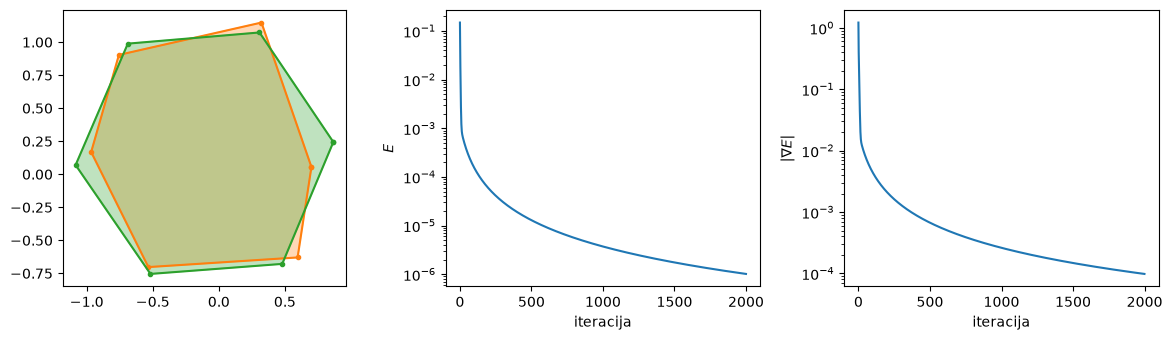

In [15]:
t_r, E_h, g_h = gradientni_spust(t0, ref, eta=0.1)
fig = plt.figure(figsize=(12, 3.5))
ax = fig.add_subplot(131)
narisi_celico(ax, t0, "tab:orange")
narisi_celico(ax, t_r, "tab:green")
ax = fig.add_subplot(132)
ax.semilogy(E_h)
ax.set_xlabel("iteracija")
ax.set_ylabel("$E$")
ax = fig.add_subplot(133)
ax.semilogy(g_h)
ax.set_xlabel("iteracija")
ax.set_ylabel(r"$|\nabla E|$")
fig.tight_layout()
plt.show()

# Naloga 3 - Slika 4

ploščine: [2.598 2.858 3.118 3.377 3.637 3.897 4.157 4.417 4.677 4.936 5.196]
energija po rasti: 5.0e-13, polmer: 1.414


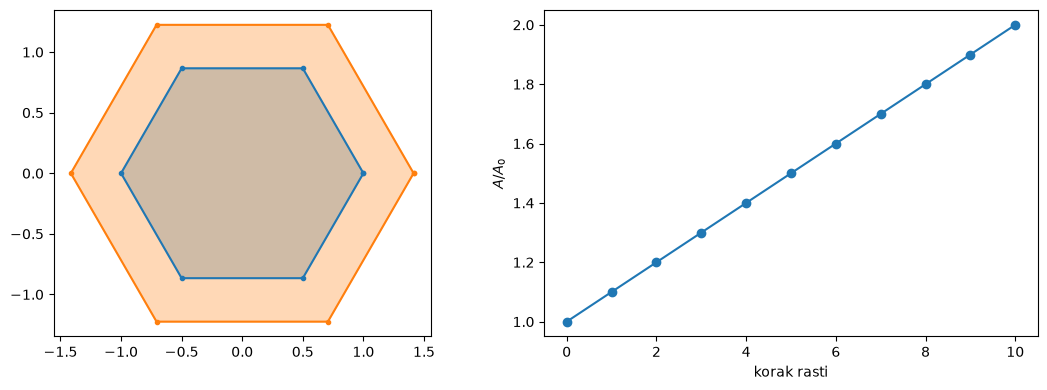

In [16]:
# Tkivo z eno celico: pravilni šestkotnik
tocke = poligon(R, n)
celice = [list(range(n))]
A0 = [ref[0]]
tocke_vel, A0_vel, A_zg = rast(tocke, celice, A0, rastoce=[0], faktor=2.0, koraki=10)
print("ploščine:", np.round(A_zg[:, 0], 3))
print(f"energija po rasti: {energija_tkiva(tocke_vel, celice, A0_vel):.1e}, "
      f"polmer: {np.linalg.norm(tocke_vel - tezisce(tocke_vel), axis=1).mean():.3f}")
fig = plt.figure(figsize=(11, 4))
ax = fig.add_subplot(121)
narisi_celico(ax, tocke, "tab:blue")
narisi_celico(ax, tocke_vel, "tab:orange")
ax = fig.add_subplot(122)
ax.plot(A_zg[:, 0] / A_zg[0, 0], "o-")
ax.set_xlabel("korak rasti")
ax.set_ylabel("$A/A_0$")
fig.tight_layout()
plt.show()

# Naloga 4 - Slika 5

kot = 15.4°, novi točki: 6, 7, celice: [[6, 1, 2, 3, 7], [7, 4, 5, 0, 6]], skupne točke: [6, 7]
ploščini po delitvi: [np.float64(2.598), np.float64(2.598)]
ploščini po relaksaciji: [np.float64(2.592), np.float64(2.592)] (A0 = 2.598), E: 2.908 -> 5.3e-05
skupna stranica: 1.230


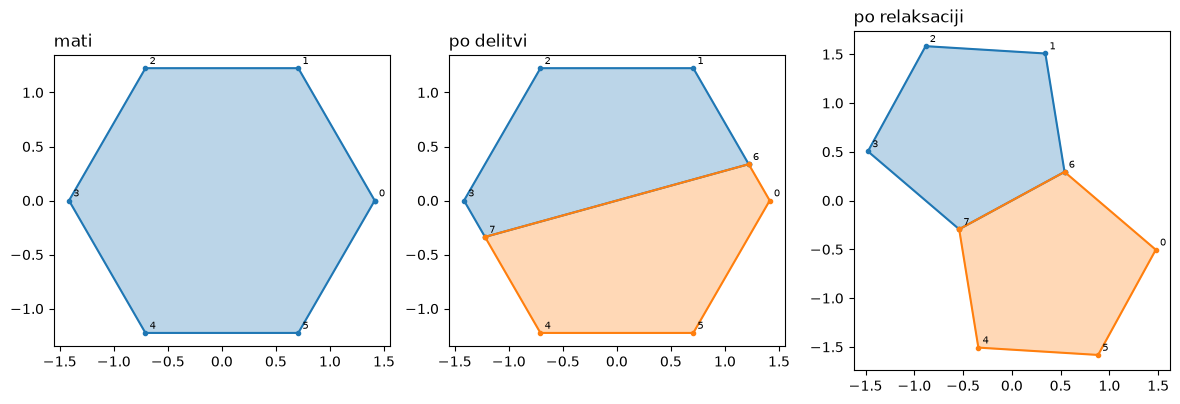

In [17]:
rng_d = np.random.default_rng(3)
kot = rng_d.uniform(0, np.pi)                    # naključna smer premice skozi težišče
celice1 = [list(c) for c in celice]
tocke1, celice1, (m1, m2) = deli_celico(tocke_vel, celice1, 0, kot)
skupne = set(celice1[0]) & set(celice1[1])
print(f"kot = {np.degrees(kot):.1f}°, novi točki: {m1}, {m2}, celice: {celice1}, skupne točke: {sorted(skupne)}")
print("ploščini po delitvi:", [round(ploscina(tocke1[c]), 3) for c in celice1])
A0_1 = [ref[0], ref[0]]                          # hčeri želita ploščino prvotne celice
tocke1_r, E1 = relaksacija_tkiva(tocke1, celice1, A0_1, eta=0.05, n_iter=1000)
print("ploščini po relaksaciji:", [round(ploscina(tocke1_r[c]), 3) for c in celice1],
      f"(A0 = {ref[0]:.3f}), E: {E1[0]:.3f} -> {E1[-1]:.1e}")
print(f"skupna stranica: {np.linalg.norm(tocke1_r[m1] - tocke1_r[m2]):.3f}")
fig = plt.figure(figsize=(12, 4))
for k, (T_, C_, naslov) in enumerate(((tocke_vel, celice, "mati"), (tocke1, celice1, "po delitvi"),
                                      (tocke1_r, celice1, "po relaksaciji"))):
    ax = fig.add_subplot(1, 3, k + 1)
    narisi_tkivo(ax, T_, C_, oznake=True)
    ax.set_title(naslov, loc="left")
fig.tight_layout()
plt.show()

# Naloga 4 - Slika 6

celic: 4, točk: 12, E: 6.903 -> 1.1e-01
celica 0: oglišč = 5, A = 2.590, indeksi = [8, 1, 2, 3, 9]
celica 1: oglišč = 4, A = 2.513, indeksi = [10, 0, 6, 11]
celica 2: oglišč = 5, A = 2.554, indeksi = [9, 7, 11, 6, 8]
celica 3: oglišč = 5, A = 2.554, indeksi = [11, 7, 4, 5, 10]


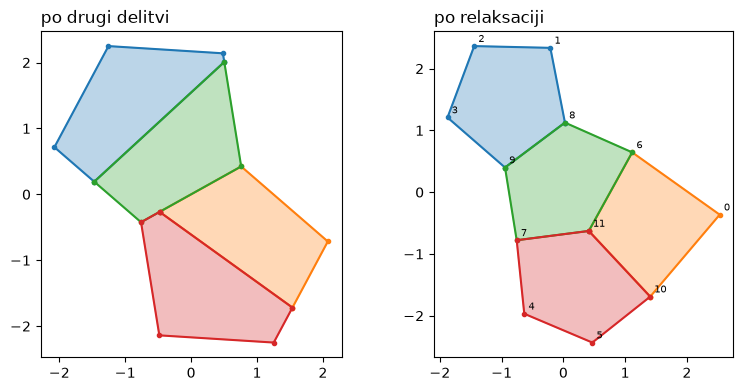

In [18]:
tocke2, A0_2, _ = rast(tocke1_r, celice1, A0_1, rastoce=[0, 1], faktor=2.0, koraki=10)
celice2 = [list(c) for c in celice1]
for k in (0, 1):
    tocke2, celice2, _ = deli_celico(tocke2, celice2, k, rng_d.uniform(0, np.pi))
tocke2_r, E2 = relaksacija_tkiva(tocke2, celice2, [ref[0]] * len(celice2), eta=0.05, n_iter=2000)
print(f"celic: {len(celice2)}, točk: {len(tocke2_r)}, E: {E2[0]:.3f} -> {E2[-1]:.1e}")
for k, c in enumerate(celice2):
    print(f"celica {k}: oglišč = {len(c)}, A = {ploscina(tocke2_r[c]):.3f}, indeksi = {c}")
fig = plt.figure(figsize=(8, 4))
ax = fig.add_subplot(121)
narisi_tkivo(ax, tocke2, celice2)
ax.set_title("po drugi delitvi", loc="left")
ax = fig.add_subplot(122)
narisi_tkivo(ax, tocke2_r, celice2, oznake=True)
ax.set_title("po relaksaciji", loc="left")
fig.tight_layout()
plt.show()